# RQ3 Analysis: Measure of Textual Lexical Diversity (MTLD)

Compares the lexical diversity (MTLD) of human-written vs. LLM-generated PR descriptions.

- Uses **TAALED** (Tool for the Automatic Analysis of Lexical Diversity) to compute MTLD.
- MTLD = mean length of sequential word strings that maintain a TTR ≥ 0.72 (McCarthy & Jarvis, 2010).
- Reports both **MTLD Original** (`mtldo` — forward-only) and **MTLD Bidirectional** (`mtld` — average of forward + backward).
- Uses `nltk.word_tokenize` for tokenization (consistent with TTR notebook).
- Compares across models and prompt context variations.

**Reference:** McCarthy, P. M., & Jarvis, S. (2010). MTLD, vocd-D, and HD-D: A validation study of sophisticated approaches to lexical diversity assessment. *Behavior Research Methods*, 42(2), 381–392.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.tokenize import word_tokenize
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp


plotnine has not been installed.
To enable advanced data visualization features, please install plotnine.


In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

In [85]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']
Human entries: 308, AI entries: 5528


## 2. Compute MTLD using TAALED

TAALED's `lexdiv` class computes multiple MTLD variants:
- **`mtldo`** — Original MTLD (forward-only pass; McCarthy & Jarvis, 2010)
- **`mtld`** / **`mtldav`** — Bidirectional MTLD (average of forward + backward passes)

We use `nltk.word_tokenize` for tokenization (consistent with the TTR notebook) and pass lowercased tokens to TAALED. Texts with fewer than 10 tokens are excluded as MTLD is unreliable for very short texts.

In [8]:
def _mtld_one_direction(tokens, thr=0.720):
    """Single-pass MTLD (McCarthy & Jarvis, 2010)."""
    if not tokens:
        return np.nan
    factor_count = 0.0
    seen = set()
    n = 0
    total = len(tokens)
    for tok in tokens:
        n += 1
        seen.add(tok)
        ttr = len(seen) / n
        if ttr <= thr:
            factor_count += 1.0
            seen = set()
            n = 0
    if n > 0:
        ttr = len(seen) / n
        factor_count += (1.0 - ttr) / (1.0 - thr)
    if factor_count == 0:
        return np.nan
    return total / factor_count


def compute_mtld(text: str) -> dict:
    """Compute MTLD Original (forward) and Bidirectional (average of forward + backward)."""
    if pd.isna(text) or str(text).strip() == '':
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}
    tokens = word_tokenize(str(text).lower())
    if len(tokens) < 10:
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}
    try:
        fwd = _mtld_one_direction(tokens)
        bwd = _mtld_one_direction(list(reversed(tokens)))
        bidir = (fwd + bwd) / 2 if not (np.isnan(fwd) or np.isnan(bwd)) else np.nan
        return {'mtld_original': fwd, 'mtld_bidir': bidir}
    except Exception:
        return {'mtld_original': np.nan, 'mtld_bidir': np.nan}


In [9]:
# Apply to both subsets
human_mtld = human_df['text'].apply(compute_mtld).apply(pd.Series)
human_df = pd.concat([human_df, human_mtld], axis=1)

ai_mtld = ai_df['text'].apply(compute_mtld).apply(pd.Series)
ai_df = pd.concat([ai_df, ai_mtld], axis=1)

In [88]:
# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})
combined_df = combined_df.dropna(subset=['mtld_original'])

In [89]:
print("MTLD metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
display(combined_df[['entry_type', 'model', 'text', 'mtld_original', 'mtld_bidir']].head(10))

MTLD metrics computed.
Combined dataset size: 5717


,entry_type,model,text,mtld_original,mtld_bidir
0,human,Human,Fixes #8873 \r\n\r\n\r\n<!-- \r\n- Go through ...,47.474312,49.489630
1,human,Human,"Implements #1516. Selected fields (`ISBN`, `UR...",20.333333,24.200000
2,human,Human,"Fixes #8108 \r\n\r\nTheoretically works, but n...",54.820163,56.829911
3,human,Human,Fixes #3905\r\n\r\n<!-- describe the changes y...,43.122664,47.588500
5,human,Human,Fixes #8654\r\nThis allows for the right click...,54.399691,55.806815
6,human,Human,# Changed database structure: table names are ...,35.712130,37.353500
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,77.440000,77.440000
8,human,Human,Fixes #3584\r\n\r\n(No changelod needed as thi...,47.434293,65.506667
9,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,87.808000,87.808000
10,human,Human,Fix #1776 remove Cookie Handler implementation...,125.692000,125.692000


## 3. Descriptive Statistics: Human vs AI (Overall)

In [90]:
print(f"\n{'='*60}")
print("  MTLD (Original) — Descriptive Statistics")
print(f"{'='*60}")


  MTLD (Original) — Descriptive Statistics


In [91]:
stats = combined_df.groupby('source')['mtld_original'].describe()
stats['median'] = combined_df.groupby('source')['mtld_original'].median()
display(stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5420.0,67.091103,26.570211,0.0,50.942724,65.252014,81.000000,304.92,65.252014
Human,297.0,57.859436,20.701365,0.0,47.272677,54.399691,65.248843,189.28,54.399691


In [92]:
for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['mtld_original']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

print()
print(f"{'='*60}")
print("  MTLD (Bidirectional) — Descriptive Statistics")
print(f"{'='*60}")

for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['mtld_bidir']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

  Human: Q1=47.2727, Median=54.3997, Q3=65.2488, IQR=17.9762
  AI: Q1=50.9427, Median=65.2520, Q3=81.0000, IQR=30.0573

  MTLD (Bidirectional) — Descriptive Statistics
  Human: Q1=48.1680, Median=57.7875, Q3=67.5968, IQR=19.4288
  AI: Q1=51.2981, Median=65.4707, Q3=81.3120, IQR=30.0139


## 4. Descriptive Statistics: By Model

In [93]:
print(f"\n{'='*60}")
print("  MTLD (Original) — By Model")
print(f"{'='*60}")


  MTLD (Original) — By Model


In [94]:
stats_model = combined_df.groupby('model')['mtld_original'].describe()
stats_model['Median'] = combined_df.groupby('model')['mtld_original'].median()
stats_model['Q1'] = combined_df.groupby('model')['mtld_original'].quantile(0.25)
stats_model['Q3'] = combined_df.groupby('model')['mtld_original'].quantile(0.75)
stats_model['IQR'] = stats_model['Q3'] - stats_model['Q1']

In [95]:
display(stats_model[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(
    columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}
))

,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,297.0,57.859436,20.701365,54.399691,47.272677,65.248843,17.976166
Qwen/Qwen2.5-72B-Instruct,1842.0,66.079681,22.420717,63.636364,51.000000,77.538462,26.538462
gpt-5-mini-2025-08-07,1842.0,77.111573,18.687224,75.492093,64.026656,87.851156,23.824501
meta-llama/llama-3.1-70b-instruct,1736.0,57.531964,33.195475,53.760000,39.390805,69.672222,30.281417


In [96]:
print(f"\n{'='*60}")
print("  MTLD (Bidirectional) — By Model")
print(f"{'='*60}")

stats_model_bi = combined_df.groupby('model')['mtld_bidir'].describe()
stats_model_bi['Median'] = combined_df.groupby('model')['mtld_bidir'].median()
stats_model_bi['Q1'] = combined_df.groupby('model')['mtld_bidir'].quantile(0.25)
stats_model_bi['Q3'] = combined_df.groupby('model')['mtld_bidir'].quantile(0.75)
stats_model_bi['IQR'] = stats_model_bi['Q3'] - stats_model_bi['Q1']

display(stats_model_bi[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(
    columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}
))


  MTLD (Bidirectional) — By Model


,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,297.0,59.851321,21.201985,57.787500,48.168000,67.596800,19.428800
Qwen/Qwen2.5-72B-Instruct,1842.0,66.474131,22.626699,63.859333,51.580738,78.098333,26.517595
gpt-5-mini-2025-08-07,1842.0,77.385122,19.280801,75.062639,63.728745,87.829125,24.100380
meta-llama/llama-3.1-70b-instruct,1736.0,57.577961,33.587160,53.816000,38.896944,70.036053,31.139108


## 5. Statistical Testing & Effect Size

In [97]:
def cliffs_delta(lst1: list, lst2: list) -> float:
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

In [98]:
def interpret_cliffs_delta(d: float) -> str:
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

In [99]:
model_results = []

In [100]:
human_mtld_orig = combined_df[combined_df['source'] == 'Human']['mtld_original'].values
human_mtld_bi = combined_df[combined_df['source'] == 'Human']['mtld_bidir'].values

In [101]:
for model in ai_df['model'].unique():
    model_data = ai_df[ai_df['model'] == model].dropna(subset=['mtld_original'])

    for metric, col, human_vals in [
        ('MTLD Original', 'mtld_original', human_mtld_orig),
        ('MTLD Bidirectional', 'mtld_bidir', human_mtld_bi),
    ]:
        ai_vals = model_data[col].values

        stat, p = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
        cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())

        model_results.append({
            'Model': model,
            'Metric': metric,
            'Human Mean': round(np.mean(human_vals), 4),
            'Model Mean': round(np.mean(ai_vals), 4),
            'Human Median': round(np.median(human_vals), 4),
            'Model Median': round(np.median(ai_vals), 4),
            'U-Statistic': stat,
            'p-value': p,
            'Significant': 'Yes' if p < 0.05 else 'No',
            "Cliff's Delta": round(cd, 4),
            'Effect Size': interpret_cliffs_delta(cd)
        })

In [102]:
models = ai_df['model'].unique()

In [103]:
print(models)
model_results_df = pd.DataFrame(model_results)
display(model_results_df)

['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']


,Model,Metric,Human Mean,Model Mean,Human Median,Model Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,meta-llama/llama-3.1-70b-instruct,MTLD Original,57.8594,57.5320,54.3997,53.7600,272307.5,1.205589e-01,No,0.0563,Negligible
1,meta-llama/llama-3.1-70b-instruct,MTLD Bidirectional,59.8513,57.5780,57.7875,53.8160,287250.5,1.626677e-03,Yes,0.1143,Negligible
2,gpt-5-mini-2025-08-07,MTLD Original,57.8594,77.1116,54.3997,75.4921,103675.0,2.790734e-66,Yes,-0.6210,Large
3,gpt-5-mini-2025-08-07,MTLD Bidirectional,59.8513,77.3851,57.7875,75.0626,120095.0,2.019402e-54,Yes,-0.5610,Large
4,Qwen/Qwen2.5-72B-Instruct,MTLD Original,57.8594,66.0797,54.3997,63.6364,200230.5,1.156701e-13,Yes,-0.2680,Small
5,Qwen/Qwen2.5-72B-Instruct,MTLD Bidirectional,59.8513,66.4741,57.7875,63.8593,217749.5,1.623342e-08,Yes,-0.2039,Small


## 6. Visualizations

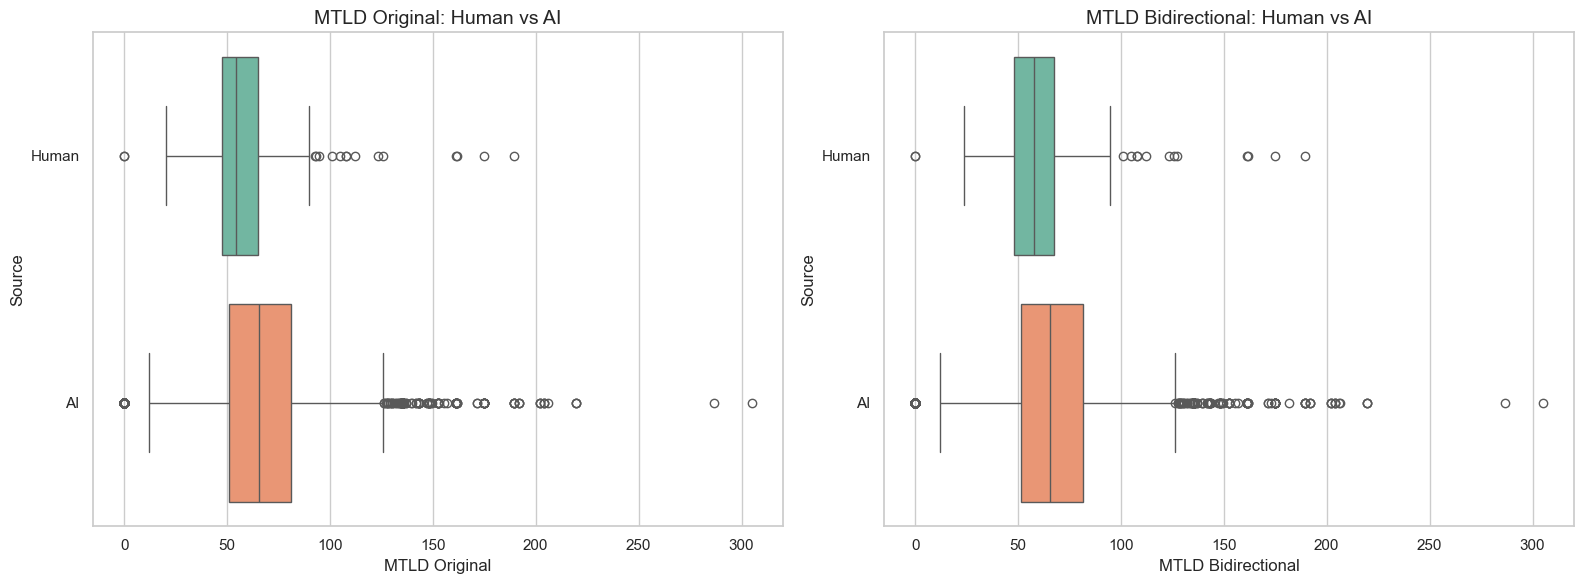

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=combined_df, x='mtld_original', y='source', hue='source',
            palette='Set2', legend=False, ax=axes[0])
axes[0].set_xlabel("MTLD Original", fontsize=12)
axes[0].set_ylabel("Source", fontsize=12)

sns.boxplot(data=combined_df, x='mtld_bidir', y='source', hue='source',
            palette='Set2', legend=False, ax=axes[1])
axes[1].set_xlabel("MTLD Bidirectional", fontsize=12)
axes[1].set_ylabel("Source", fontsize=12)

plt.tight_layout()
plt.show()

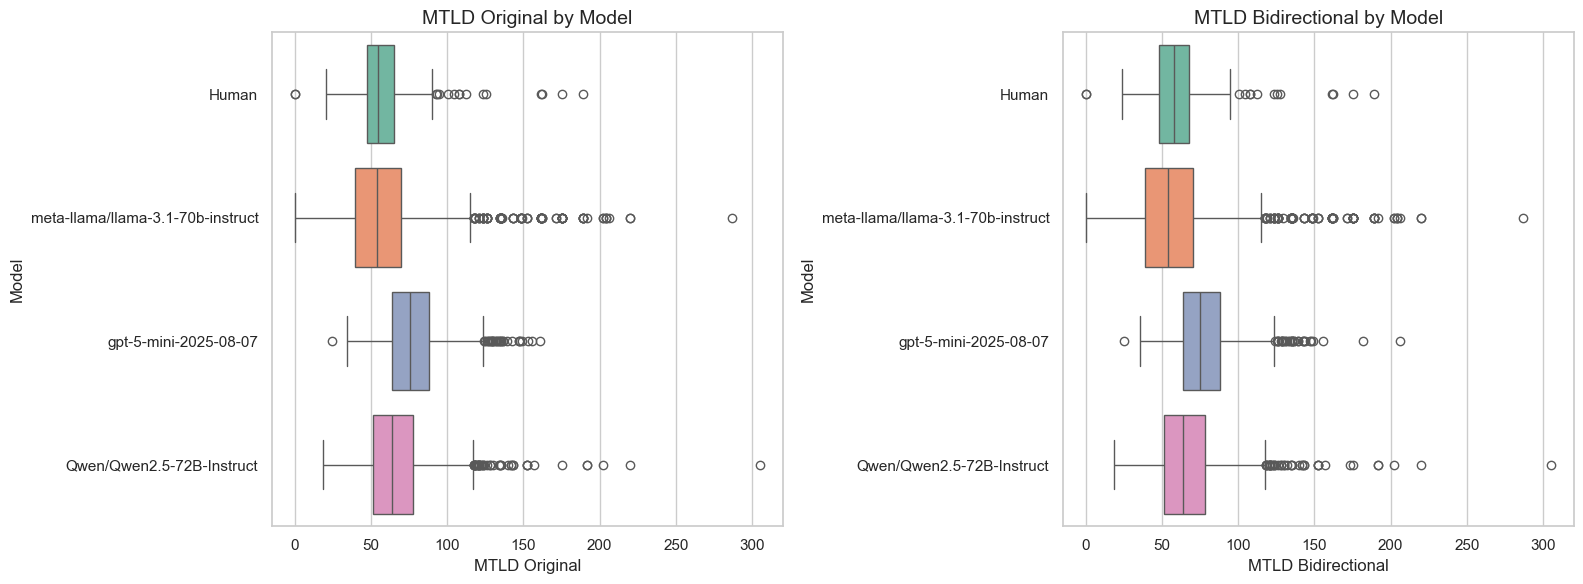

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

order = ['Human'] + list(models)

sns.boxplot(data=combined_df, x='mtld_original', y='model', order=order,
            hue='model', palette='Set2', legend=False, ax=axes[0])
axes[0].set_xlabel("MTLD Original", fontsize=12)
axes[0].set_ylabel("Model", fontsize=12)

sns.boxplot(data=combined_df, x='mtld_bidir', y='model', order=order,
            hue='model', palette='Set2', legend=False, ax=axes[1])
axes[1].set_xlabel("MTLD Bidirectional", fontsize=12)
axes[1].set_ylabel("Model", fontsize=12)

plt.tight_layout()
plt.show()

## 7. MTLD Boxplots by Context per LLM (with Human Baseline)

This mirrors the word-count, sentence-count, FKGL, and TTR setup:

- One panel per LLM model (stacked vertically).
- Each panel includes 6 AI context boxplots.
- A Human baseline boxplot is included in each panel for direct comparison.
- Rendered for both MTLD variants: `mtld_original` and `mtld_bidir`.

In [106]:
print(f"\n{'='*60}")
print("  MTLD (Original) — By Prompt Context Variation")
print(f"{'='*60}")


  MTLD (Original) — By Prompt Context Variation


In [107]:
# Filter to only AI data since 'human' entries don't have variation context
context_df = combined_df[combined_df['source'] == 'AI'].copy()
stats_ctx = context_df.groupby('Context_Name')['mtld_original'].describe()
stats_ctx['median'] = context_df.groupby('Context_Name')['mtld_original'].median()
display(stats_ctx)

,count,mean,std,min,25%,50%,75%,max,median
Context_Name,,,,,,,,,
File Contents,899.0,61.937032,21.653413,0.0,46.779479,60.424201,74.956138,136.786087,60.424201
File Diff,914.0,61.195967,24.856239,0.0,46.959315,59.583506,73.927523,206.173333,59.583506
Linked Issue,923.0,74.025897,24.967001,0.0,58.394155,71.384733,87.372811,219.520000,71.384733
PR Title,922.0,77.481096,35.561506,0.0,60.480000,74.666667,91.593939,304.920000,74.666667
Repo Path,845.0,61.799353,24.917880,0.0,44.535540,61.500000,77.069323,161.146770,61.500000
Without File Contents,917.0,65.469298,19.587245,0.0,52.074468,63.806902,78.529630,136.080000,63.806902


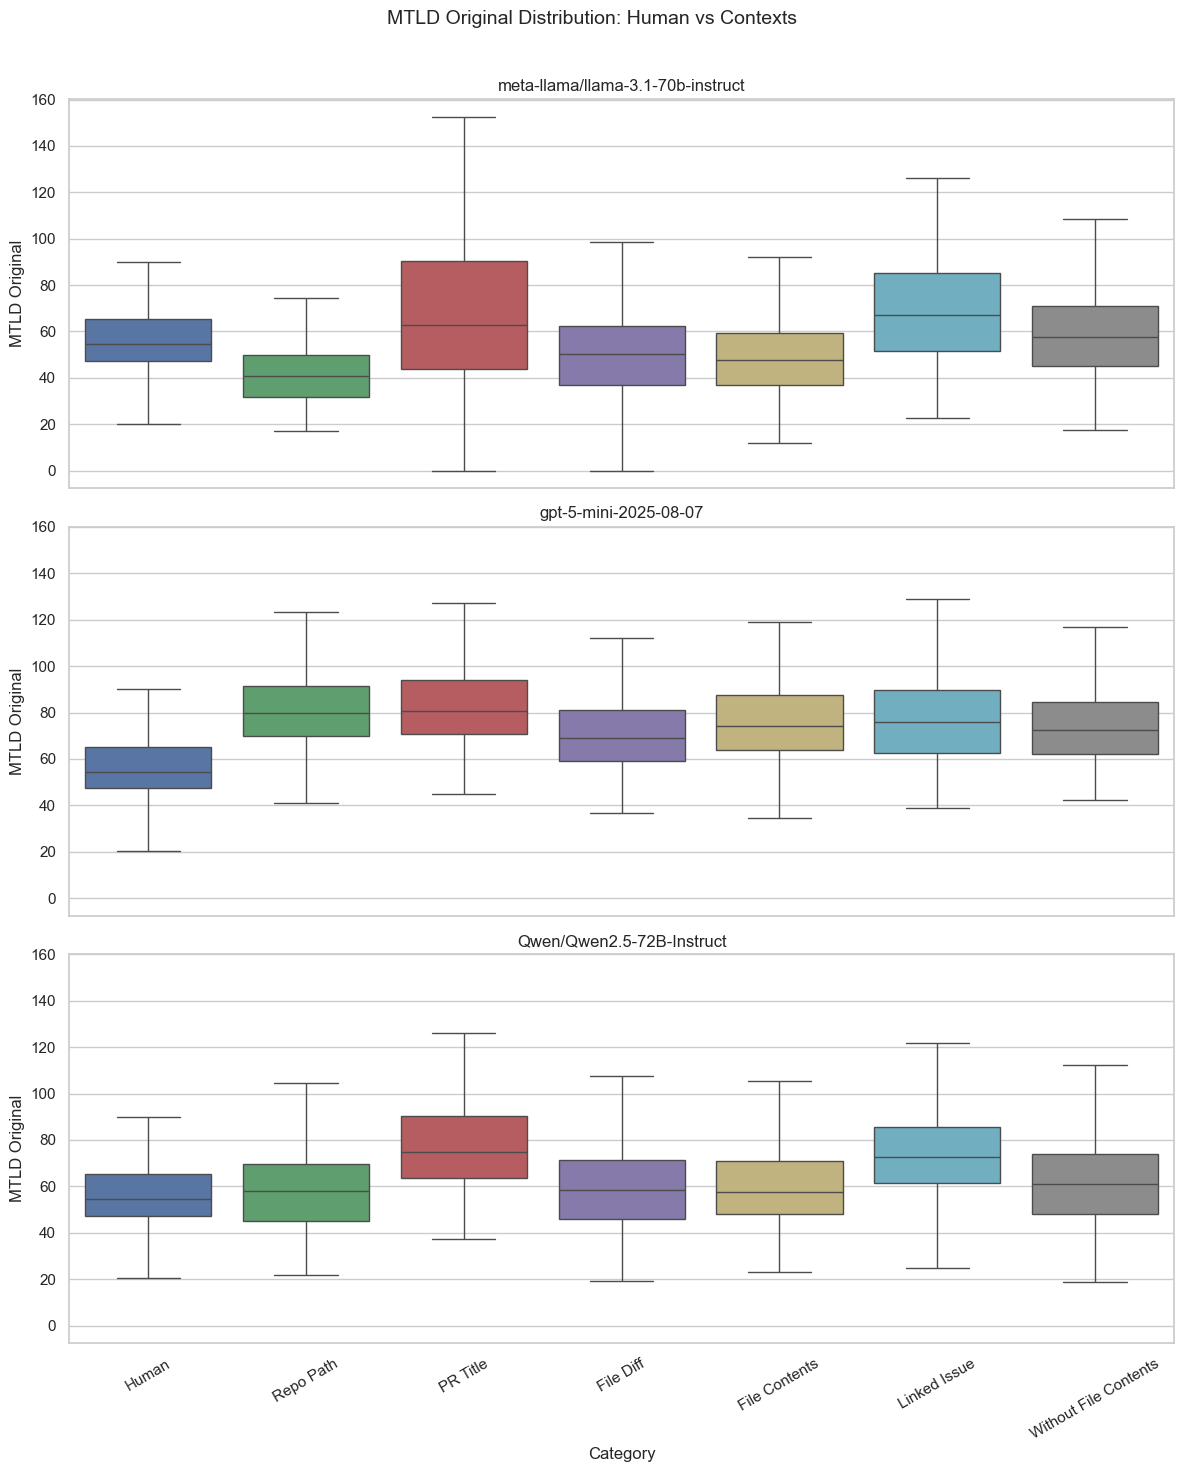

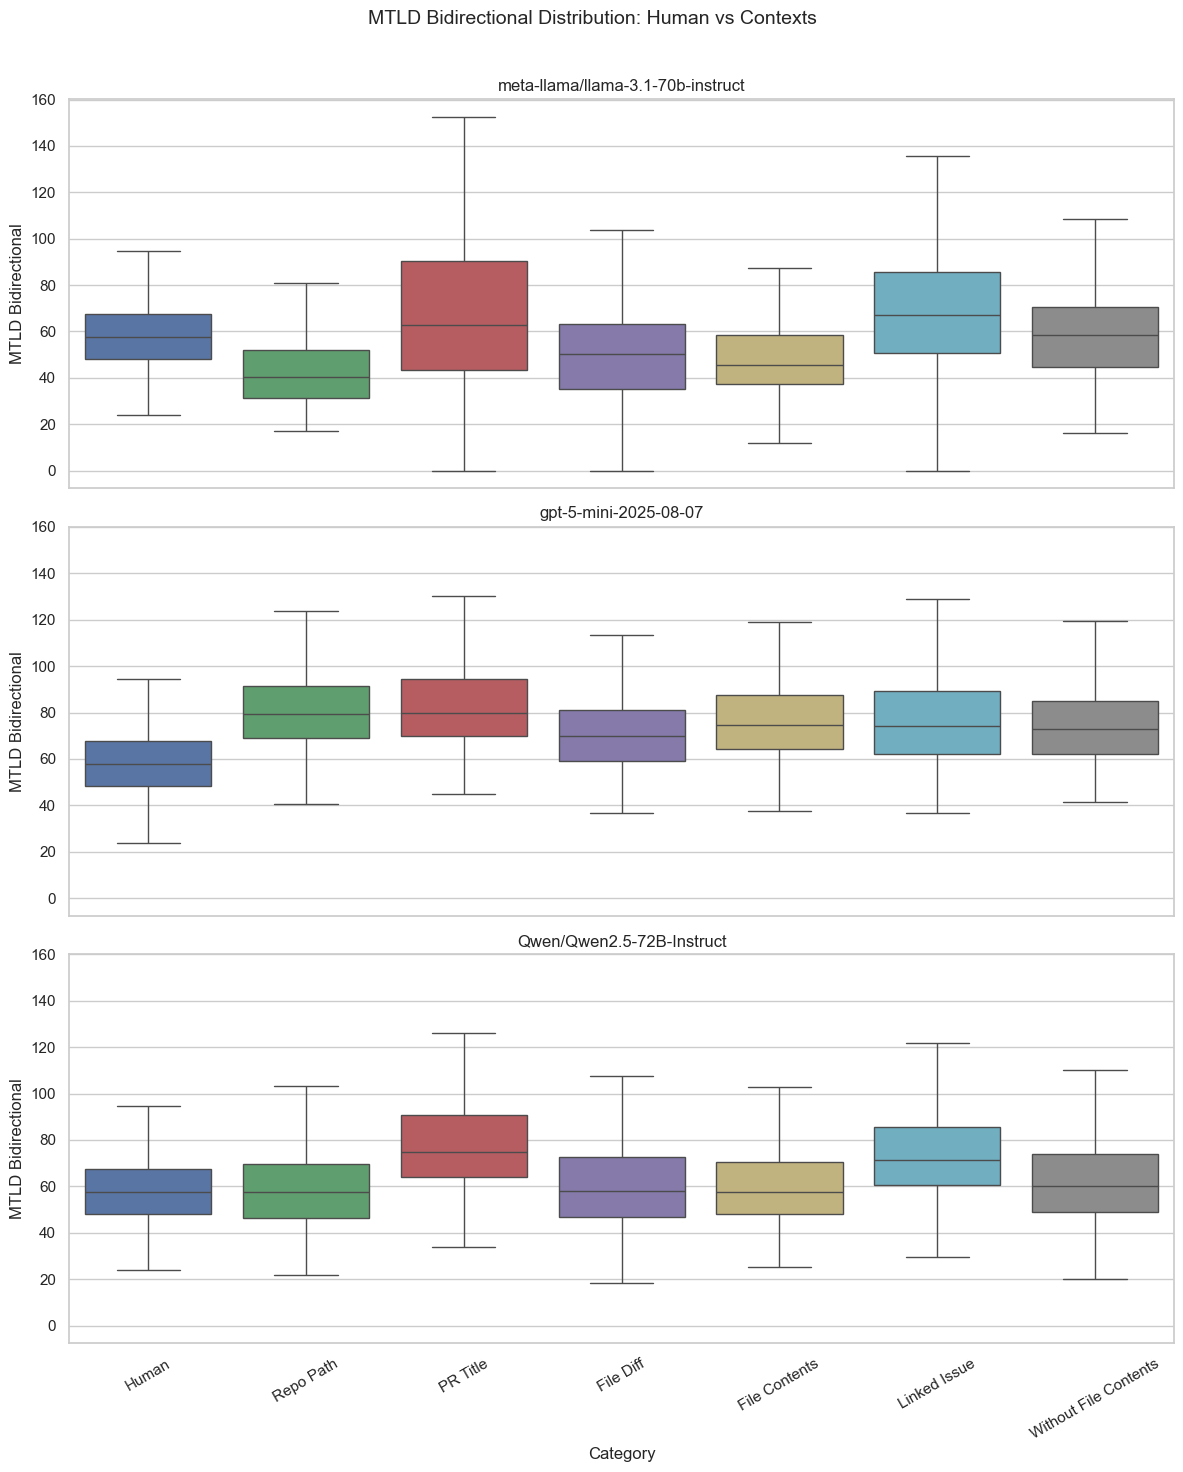

In [10]:
from pathlib import Path
OUT_DIR = Path('outputs/figures_pdf')
OUT_DIR.mkdir(parents=True, exist_ok=True)
context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

def plot_mtld_by_context(metric_col: str, y_label: str, figure_title: str) -> None:
    fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)

    if len(llm_models) == 1:
        axes = [axes]

    for i, model in enumerate(llm_models):
        ax = axes[i]
        ax.set_title(model, fontsize=14)

        ai_slice = ai_df[ai_df['model'] == model][[metric_col, 'Context_Name']].dropna().copy()
        ai_slice['Category'] = ai_slice['Context_Name']

        human_slice = human_df[[metric_col]].dropna().copy()
        human_slice['Category'] = 'Human'

        panel_df = pd.concat([
            human_slice[[metric_col, 'Category']],
            ai_slice[[metric_col, 'Category']]
        ], ignore_index=True)

        sns.boxplot(
            data=panel_df,
            x='Category',
            y=metric_col,
            order=x_order,
            hue='Category',
            hue_order=x_order,
            ax=ax,
            palette=palette_map,
            dodge=False,
            legend=False,
            showfliers=False
        )

        ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
        ax.set_ylabel(y_label, fontsize=14)
        ax.tick_params(axis='x', rotation=30, labelsize=12)

    plt.tight_layout()
    plt.savefig(str(OUT_DIR / (figure_title.replace(' ', '_').replace(':', '') + '.pdf')), bbox_inches='tight', dpi=150)
    plt.show()

plot_mtld_by_context('mtld_original', 'MTLD Original', 'MTLD Original Distribution: Human vs Contexts')
plot_mtld_by_context('mtld_bidir', 'MTLD Bidirectional', 'MTLD Bidirectional Distribution: Human vs Contexts')

## 8. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for MTLD.

In [109]:
print(f"\n{'='*90}")
print("  Cliff's δ Effect Sizes: Human vs. AI Context Variations (MTLD)")
print(f"{'='*90}")


  Cliff's δ Effect Sizes: Human vs. AI Context Variations (MTLD)


In [110]:
model_names = ai_df['model'].unique()
variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

In [111]:
rows_orig = []
rows_bidir = []

for model in model_names:
    row_orig = {'Model': model}
    row_bidir = {'Model': model}

    for variation in variation_names:
        # AI values for this model + variation (only paired PRs)
        ai_vals_orig = ai_df[
            (ai_df['model'] == model) & (ai_df['Context_Name'] == variation)
        ]['mtld_original'].dropna().values

        ai_vals_bidir = ai_df[
            (ai_df['model'] == model) & (ai_df['Context_Name'] == variation)
        ]['mtld_bidir'].dropna().values

        # Human values for the same paired PRs
        human_vals_orig = human_df['mtld_original'].dropna().values
        human_vals_bidir = human_df['mtld_bidir'].dropna().values

        # Compute Cliff's delta — MTLD Original
        delta_orig = cliffs_delta(list(human_vals_orig), list(ai_vals_orig))
        interp_orig = interpret_cliffs_delta(delta_orig)
        row_orig[variation] = f"{delta_orig:.3f} ({interp_orig})"

        # Compute Cliff's delta — MTLD Bidirectional
        delta_bidir = cliffs_delta(list(human_vals_bidir), list(ai_vals_bidir))
        interp_bidir = interpret_cliffs_delta(delta_bidir)
        row_bidir[variation] = f"{delta_bidir:.3f} ({interp_bidir})"

    rows_orig.append(row_orig)
    rows_bidir.append(row_bidir)

In [112]:
print("MTLD Original — Cliff's δ by Model × Context:")
result_orig_df = pd.DataFrame(rows_orig).set_index('Model')
display(result_orig_df)

print("\nMTLD Bidirectional — Cliff's δ by Model × Context:")
result_bidir_df = pd.DataFrame(rows_bidir).set_index('Model')
display(result_bidir_df)

MTLD Original — Cliff's δ by Model × Context:


,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,0.525 (Large),-0.164 (Small),0.204 (Small),0.273 (Small),-0.307 (Small),-0.065 (Negligible)
gpt-5-mini-2025-08-07,-0.730 (Large),-0.723 (Large),-0.495 (Large),-0.582 (Large),-0.603 (Large),-0.592 (Large)
Qwen/Qwen2.5-72B-Instruct,-0.053 (Negligible),-0.614 (Large),-0.086 (Negligible),-0.123 (Negligible),-0.544 (Large),-0.185 (Small)



MTLD Bidirectional — Cliff's δ by Model × Context:


,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,0.556 (Large),-0.120 (Negligible),0.250 (Small),0.357 (Medium),-0.236 (Small),-0.000 (Negligible)
gpt-5-mini-2025-08-07,-0.669 (Large),-0.666 (Large),-0.429 (Medium),-0.534 (Large),-0.528 (Large),-0.539 (Large)
Qwen/Qwen2.5-72B-Instruct,0.017 (Negligible),-0.564 (Large),-0.052 (Negligible),-0.031 (Negligible),-0.467 (Medium),-0.123 (Negligible)


## 9. Summary Table

In [113]:
summary_rows = []

In [114]:
for model in combined_df['model'].unique():
    subset = combined_df[combined_df['model'] == model]

    for metric, col in [('MTLD Original', 'mtld_original'), ('MTLD Bidirectional', 'mtld_bidir')]:
        vals = subset[col].dropna()
        summary_rows.append({
            'Model': model,
            'Metric': metric,
            'N': len(vals),
            'Mean': round(vals.mean(), 4),
            'Median': round(vals.median(), 4),
            'Std': round(vals.std(), 4),
            'Min': round(vals.min(), 4),
            'Max': round(vals.max(), 4),
            'Q1': round(vals.quantile(0.25), 4),
            'Q3': round(vals.quantile(0.75), 4)
        })

In [115]:
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,MTLD Original,297,57.8594,54.3997,20.7014,0.0000,189.2800,47.2727,65.2488
1,Human,MTLD Bidirectional,297,59.8513,57.7875,21.2020,0.0000,189.2800,48.1680,67.5968
2,meta-llama/llama-3.1-70b-instruct,MTLD Original,1736,57.5320,53.7600,33.1955,0.0000,286.7200,39.3908,69.6722
3,meta-llama/llama-3.1-70b-instruct,MTLD Bidirectional,1736,57.5780,53.8160,33.5872,0.0000,286.7200,38.8969,70.0361
4,gpt-5-mini-2025-08-07,MTLD Original,1842,77.1116,75.4921,18.6872,24.6339,161.1468,64.0267,87.8512
5,gpt-5-mini-2025-08-07,MTLD Bidirectional,1842,77.3851,75.0626,19.2808,25.3706,206.3778,63.7287,87.8291
6,Qwen/Qwen2.5-72B-Instruct,MTLD Original,1842,66.0797,63.6364,22.4207,18.6660,304.9200,51.0000,77.5385
7,Qwen/Qwen2.5-72B-Instruct,MTLD Bidirectional,1842,66.4741,63.8593,22.6267,18.5000,304.9200,51.5807,78.0983


In [116]:
import os
os.makedirs('outputs', exist_ok=True)

# Save summary to CSV
summary_df.to_csv('outputs/rq3_mtld_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_mtld_summary.csv")


Summary saved to outputs/rq3_mtld_summary.csv
